# 02 - Lesion-prioritized transmission vs normal transmission (RQ1)
Pipeline: clean mammogram -> **sender localizes the lesion** -> 32x32-pixel blocks get a priority -> lossy channel -> receiver **reconstructs** -> receiver localizes, crops and classifies.

Compared schemes (all lose exactly the same number of blocks, i.e. equal bandwidth):
* `uniform`: independent random loss (normal transmission)
* `burst`: bursty loss (contiguous runs)
* `semantic/pred`: priority-aware network, sender importance from the **predicted** lesion map (the realistic version)
* `semantic/oracle`: importance from the **true** lesion mask (upper bound, not realistic)

Two receivers: `standard` (models trained on clean images) and `robust` (trained with packet-loss augmentation).

Time: roughly 20-60 minutes on a T4 GPU, depending on the number of test images. Lower `cfg.reps` or the number of rates for a quick run.

In [1]:
# ---- 1. connect Drive, install, load the code ----
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print('Not running in Colab:', e)
!pip -q install pydicom
import sys, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
CODE_DIR = '/content/drive/MyDrive/mammo_semcom'          # <-- the folder you uploaded (contains src/ and notebooks/)
sys.path.insert(0, CODE_DIR)
from src.config import Cfg

cfg = Cfg(
    cbis_root = '/content/drive/MyDrive/CBIS-DDSM',        # raw data folder: NOT needed after notebook 00 (the cache is used)
    work_dir  = '/content/drive/MyDrive/mammo_semcom_work', # <-- all caches, models, results and figures go here
    max_images = 0,                                         # 0 = everything; try 150 first for a quick dry run
).ensure()
cfg.save()
print(cfg.work_dir)

Mounted at /content/drive
/content/drive/MyDrive/mammo_semcom_work


In [2]:
from src import data, viz, train as T
from src.pipeline import Receiver, diagnose_all
from src.metrics import *
images, masks, images_df, abn_df = data.load_cache(cfg)
tr_idx = images_df[images_df.split == 'train'].img_idx.values
va_idx = images_df[images_df.split == 'val'].img_idx.values
abn_tr = abn_df[abn_df.split == 'train'].reset_index(drop=True)
abn_va = abn_df[abn_df.split == 'val'].reset_index(drop=True)
abn_te = abn_df[abn_df.split == 'test'].reset_index(drop=True)
te_df = images_df[(images_df.split == 'test') & (~images_df.mixed)].reset_index(drop=True)   # image-level test set
print(len(tr_idx), 'train /', len(va_idx), 'val images |', len(te_df), 'test images | device:', T.DEVICE)

106 train / 22 val images | 22 test images | device: cuda


In [3]:
from src import channel as ch
from src.pipeline import *
X_te = images[te_df.img_idx.values]; M_te = masks[te_df.img_idx.values]
img01 = np.stack([T.to01(a) for a in X_te])
loc_clean, loc_robust = T.load_localizer(cfg, 'clean'), T.load_localizer(cfg, 'robust')
clf_clean, clf_robust = T.load_classifier(cfg, 'clean_0'), T.load_classifier(cfg, 'robust_0')
receivers = {'standard': Receiver(cfg, loc_clean, [clf_clean]), 'robust': Receiver(cfg, loc_robust, [clf_robust])}

# sender side: lesion map from the (clean) localizer -> block priorities
heat_te = T.predict_heatmaps(loc_clean, X_te)
importance = {s: build_importance(cfg, X_te, M_te, heat_te, s) for s in ['none', 'pred', 'oracle']}
print('test images:', len(X_te), '| blocks per image:', importance['none'][0].shape, '| transmitted blocks (mean):',
      round(np.mean([(i >= 0).sum() for i in importance['none']]), 1))

test images: 22 | blocks per image: (24, 16) | transmitted blocks (mean): 243.6


## 2. One example (30% loss)

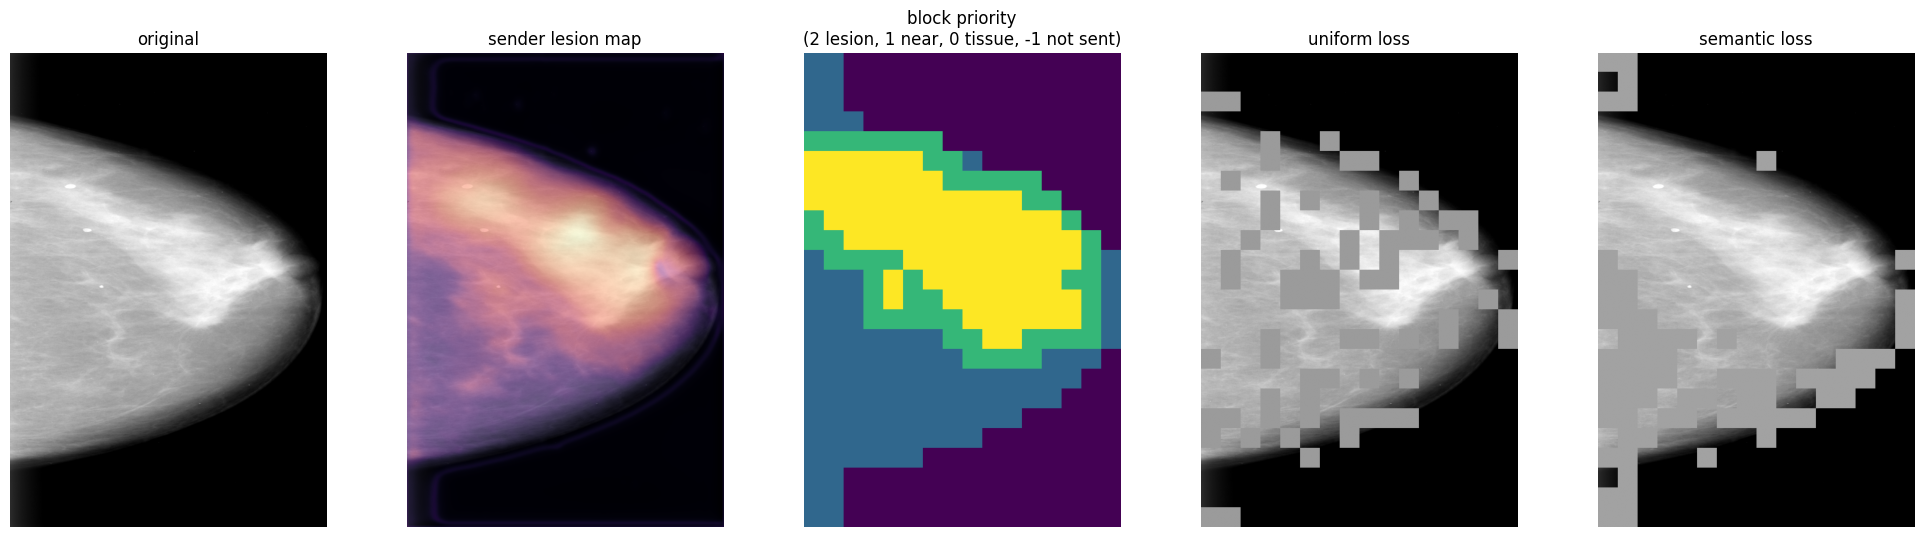

In [4]:
j = int(np.where(te_df.label.values == 1)[0][0]); rng = np.random.default_rng(1)
lost_u = ch.choose_lost(importance['none'][j], 0.3, 'uniform', rng); lost_s = ch.choose_lost(importance['pred'][j], 0.3, 'semantic', rng)
ru, _ = ch.apply_loss(img01[j], lost_u, cfg.block, cfg.recon); rs, _ = ch.apply_loss(img01[j], lost_s, cfg.block, cfg.recon)
viz.plot_loss_example(img01[j], heat_te[j].astype(np.float32), importance['pred'][j], lost_u, lost_s, cfg.block, ru, rs,
                      path=cfg.path('figures', '02_example_loss.png'))

## 3. Main experiment

In [5]:
conditions = [('uniform', 'none'), ('burst', 'none'), ('semantic', 'pred'), ('semantic', 'oracle')]
raw = run_transmission(cfg, X_te, M_te, te_df, receivers, importance, conditions)
raw.to_csv(cfg.path('results', 'transmission_raw.csv'), index=False)
summary = summarize(raw); summary.to_csv(cfg.path('results', 'transmission_summary.csv'), index=False)
summary[summary.rate.isin([0.0, 0.3, 0.5])].round(3)

done: uniform  src=none   rate=0.1
done: burst    src=none   rate=0.1
done: semantic src=pred   rate=0.1
done: semantic src=oracle rate=0.1
done: uniform  src=none   rate=0.2
done: burst    src=none   rate=0.2
done: semantic src=pred   rate=0.2
done: semantic src=oracle rate=0.2
done: uniform  src=none   rate=0.3
done: burst    src=none   rate=0.3
done: semantic src=pred   rate=0.3
done: semantic src=oracle rate=0.3
done: uniform  src=none   rate=0.4
done: burst    src=none   rate=0.4
done: semantic src=pred   rate=0.4
done: semantic src=oracle rate=0.4
done: uniform  src=none   rate=0.5
done: burst    src=none   rate=0.5
done: semantic src=pred   rate=0.5
done: semantic src=oracle rate=0.5


,receiver,scheme,source,rate,AUC,AUC_sd,sens_at_spec,loc_hit,lesion_loss,psnr_roi,ssim_roi,mean_entropy
2,robust,burst,none,0.3,0.466,0.049,0.091,0.318,0.361,42.680,0.850,0.612
4,robust,burst,none,0.5,0.532,0.074,0.000,0.242,0.524,25.006,0.784,0.611
5,robust,clean,none,0.0,0.587,0.000,0.091,0.318,0.000,99.000,1.000,0.626
8,robust,semantic,oracle,0.3,0.523,0.101,0.091,0.379,0.000,94.045,0.999,0.607
10,robust,semantic,oracle,0.5,0.504,0.060,0.152,0.333,0.000,93.083,0.998,0.627
13,robust,semantic,pred,0.3,0.609,0.069,0.091,0.333,0.134,61.628,0.930,0.623
15,robust,semantic,pred,0.5,0.537,0.065,0.091,0.348,0.266,56.454,0.887,0.624
18,robust,uniform,none,0.3,0.435,0.150,0.121,0.288,0.291,23.448,0.825,0.619
20,robust,uniform,none,0.5,0.565,0.061,0.152,0.288,0.488,20.597,0.754,0.645
23,standard,burst,none,0.3,0.521,0.115,0.273,0.242,0.361,42.680,0.850,0.587


## 4. Figures
Panels: AUC, sensitivity at 90% specificity, how often the receiver finds the lesion, and the share of lesion area that was lost. Use **AUC** as the headline metric (threshold-free).

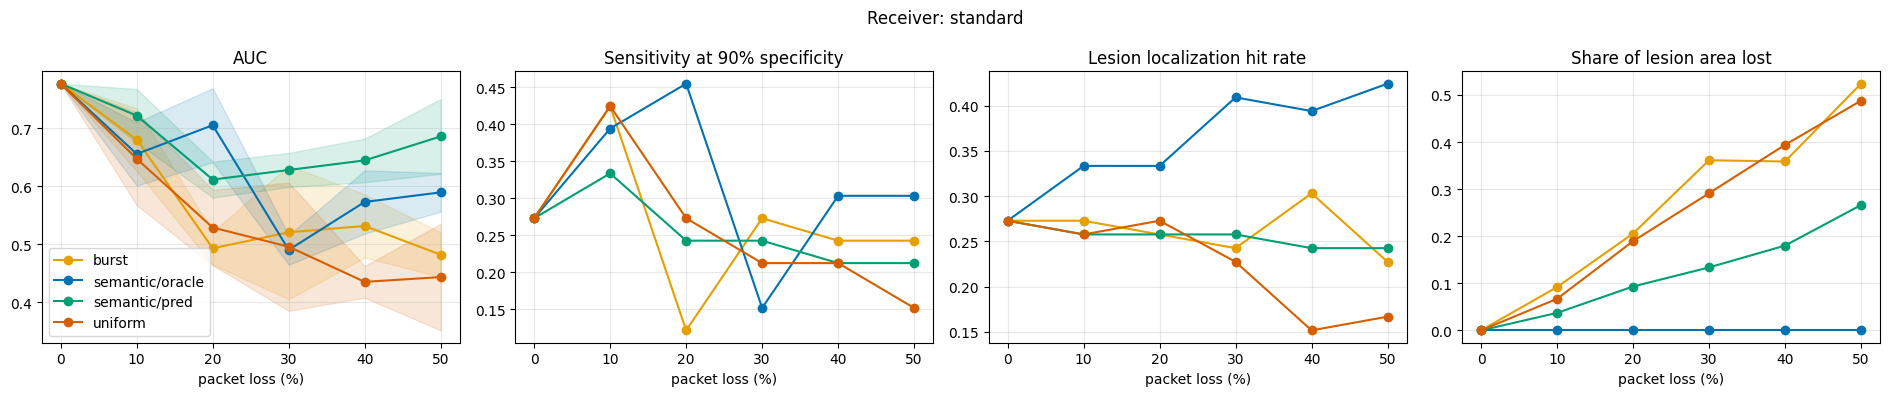

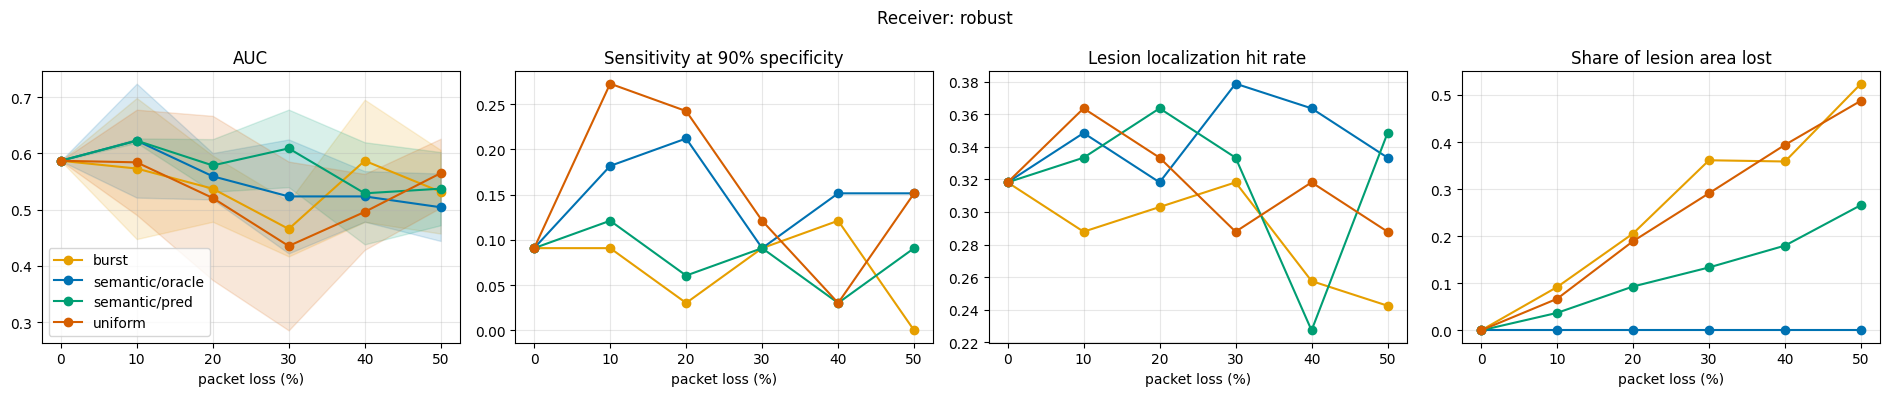

In [6]:
for rname in receivers:
    viz.plot_transmission(summary, rname, path=cfg.path('figures', f'02_transmission_{rname}.png'), title=f'Receiver: {rname}')

## 5. Statistics: patient-level bootstrap confidence intervals and paired tests

In [7]:
pairs = [(('semantic', 'pred'), ('uniform', 'none')), (('semantic', 'pred'), ('burst', 'none')), (('semantic', 'oracle'), ('semantic', 'pred'))]
stats = []
for rname in receivers:
    for rate in [r for r in cfg.loss_rates if r in (0.2, 0.3, 0.4)]:
        t = bootstrap_table(raw, rname, rate, pairs, n=1000); t.insert(0, 'rate', rate); t.insert(0, 'receiver', rname); stats.append(t)
stats = pd.concat(stats); stats.to_csv(cfg.path('results', 'transmission_stats.csv'), index=False)
stats[stats.kind == 'AUC difference'].round(3)

,receiver,rate,kind,a,b,value,ci_low,ci_high,p_value
4,standard,0.2,AUC difference,semantic/pred,uniform/none,0.149,-0.161,0.450,0.371
5,standard,0.2,AUC difference,semantic/pred,burst/none,0.140,-0.132,0.408,0.325
6,standard,0.2,AUC difference,semantic/oracle,semantic/pred,0.066,-0.183,0.341,0.650
4,standard,0.3,AUC difference,semantic/pred,uniform/none,0.207,-0.092,0.483,0.158
5,standard,0.3,AUC difference,semantic/pred,burst/none,0.107,-0.161,0.392,0.434
6,standard,0.3,AUC difference,semantic/oracle,semantic/pred,-0.207,-0.479,0.052,0.109
4,standard,0.4,AUC difference,semantic/pred,uniform/none,0.273,-0.027,0.567,0.078
5,standard,0.4,AUC difference,semantic/pred,burst/none,0.198,-0.089,0.488,0.198
6,standard,0.4,AUC difference,semantic/oracle,semantic/pred,-0.190,-0.482,0.098,0.209
4,robust,0.2,AUC difference,semantic/pred,uniform/none,0.107,-0.099,0.322,0.310


**How to read it:** `AUC difference` rows show (first scheme - second scheme). If the confidence interval excludes 0 (and the p-value is small), the difference is reliable. `semantic/oracle - semantic/pred` shows how much is lost because the sender must *predict* the lesion location.

## 6. Ablations (smaller runs at 30% loss)

In [8]:
from dataclasses import replace
sub = np.arange(min(len(X_te), 120))                       # quick subset
abl = []
# (a) block size
for b in [16, 32, 64]:
    c2 = replace(cfg, block=b)
    imp2 = {s: build_importance(c2, X_te[sub], M_te[sub], heat_te[sub], s) for s in ['none', 'pred']}
    r = run_transmission(c2, X_te[sub], M_te[sub], te_df.iloc[sub], {'standard': receivers['standard']}, imp2,
                         [('uniform', 'none'), ('semantic', 'pred')], rates=(0.3,), reps=2, verbose=False)
    s = summarize(r); s = s[s.rate == 0.3]; s.insert(0, 'ablation', f'block={b}'); abl.append(s)
# (b) reconstruction method
for rec in ['zero', 'mean', 'inpaint']:
    r = run_transmission(cfg, X_te[sub], M_te[sub], te_df.iloc[sub], {'standard': receivers['standard']},
                         {s: v[:len(sub)] for s, v in importance.items()}, [('uniform', 'none'), ('semantic', 'pred')],
                         rates=(0.3,), reps=2, recon=rec, verbose=False)
    s = summarize(r); s = s[s.rate == 0.3]; s.insert(0, 'ablation', f'recon={rec}'); abl.append(s)
abl = pd.concat(abl); abl.to_csv(cfg.path('results', 'transmission_ablations.csv'), index=False)
abl[['ablation', 'scheme', 'source', 'AUC', 'loc_hit', 'lesion_loss', 'psnr_roi']].round(3)

,ablation,scheme,source,AUC,loc_hit,lesion_loss,psnr_roi
1,block=16,semantic,pred,0.707,0.227,0.124,48.783
2,block=16,uniform,none,0.339,0.227,0.263,22.548
1,block=32,semantic,pred,0.769,0.227,0.143,64.592
2,block=32,uniform,none,0.475,0.227,0.306,22.875
1,block=64,semantic,pred,0.802,0.273,0.133,78.587
2,block=64,uniform,none,0.492,0.250,0.294,40.343
1,recon=zero,semantic,pred,0.574,0.273,0.143,58.138
2,recon=zero,uniform,none,0.409,0.182,0.306,10.740
1,recon=mean,semantic,pred,0.769,0.227,0.143,64.592
2,recon=mean,uniform,none,0.496,0.227,0.306,22.875


## Done
Interpretation checklist for your write-up:
* Does `semantic/pred` stay above `uniform` and `burst` as loss grows? (main claim)
* How far is `semantic/pred` from `semantic/oracle`? (cost of predicting the lesion)
* Does the `robust` receiver shrink the gap? (robust training)
* Sensitivity/specificity at a fixed threshold are distorted by gray filled-in blocks; rely on AUC and sensitivity at fixed specificity.
* Equal bandwidth: every scheme loses the same number of blocks. The priority tag costs about 2 bits per block (negligible); state it.

Next: `03_uncertainty_and_adaptive_loop.ipynb`.